# Potato Leaf Disease Classification — End-to-End ML Pipeline

**Use case.** Irish potato is one of Rwanda's most important staple crops, and blight can destroy a field within days.
Extension officers and farmers rarely have a plant pathologist on hand. This project trains an image classifier
that tells, from a single photo of a leaf, whether the plant is **healthy**, has **early blight** (*Alternaria solani*)
or **late blight** (*Phytophthora infestans*). The model is then served through an API and a web UI, and it can be
retrained as new labelled field photos arrive.

**Data.** The potato subset of the open PlantVillage dataset (Hughes & Salathé, 2015; CC BY-SA 3.0):
2,152 colour leaf photos in 3 classes.

| Notebook section | Pipeline step |
|---|---|
| 1 | Data acquisition |
| 2 | Exploratory analysis & feature interpretation |
| 3 | Data preprocessing |
| 4 | Model creation (baseline vs optimised CNN) |
| 5 | Model testing / evaluation (accuracy, loss, precision, recall, F1, ROC-AUC, confusion matrix) |
| 6 | Prediction functions |
| 7 | Retraining demonstration (fine-tuning the saved model on new data) |

In [1]:
import os, sys, json, time, random
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, ConfusionMatrixDisplay, classification_report

from src.config import CLASSES, CLASS_DISPLAY, TRAIN_DIR, TEST_DIR, INCOMING_DIR, IMG_SIZE, SEED
from src import preprocessing as prep
from src import model as M
from src.insights import feature_table, save_insights, FEATURES

keras.utils.set_random_seed(SEED)
FIG_DIR = ROOT / "docs" / "images"; FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
PALETTE = {"Early Blight": "#d08c2b", "Healthy": "#3a8f4b", "Late Blight": "#6b4f9e"}
print("TensorFlow", tf.__version__, "| classes:", CLASSES, "| image size:", IMG_SIZE)

I0000 00:00:1795174336.416893    1256 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795174337.517073    1256 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | classes: ['early_blight', 'healthy', 'late_blight'] | image size: 128


## 1. Data acquisition

`src/data_acquisition.py` does a sparse `git clone` of only the three potato folders of
[PlantVillage](https://github.com/spMohanty/PlantVillage-Dataset) and makes a **stratified, seeded** split:

* `data/train` (70 %): model building (a validation set is carved out of it below)
* `data/test` (15 %): held-out test set, never seen during training or retraining
* `data/incoming` (15 %): kept aside to **simulate new field data** that a user uploads to trigger retraining

```bash
python -m src.data_acquisition
```

In [2]:
counts = pd.DataFrame({split: {CLASS_DISPLAY[c]: len(list((ROOT/'data'/split/c).glob('*'))) for c in CLASSES}
                       for split in ["train", "test", "incoming"]})
counts.loc["Total"] = counts.sum()
counts

,train,test,incoming
Early Blight,700,150,150
Healthy,106,22,24
Late Blight,700,150,150
Total,1506,322,324


## 2. Exploratory data analysis

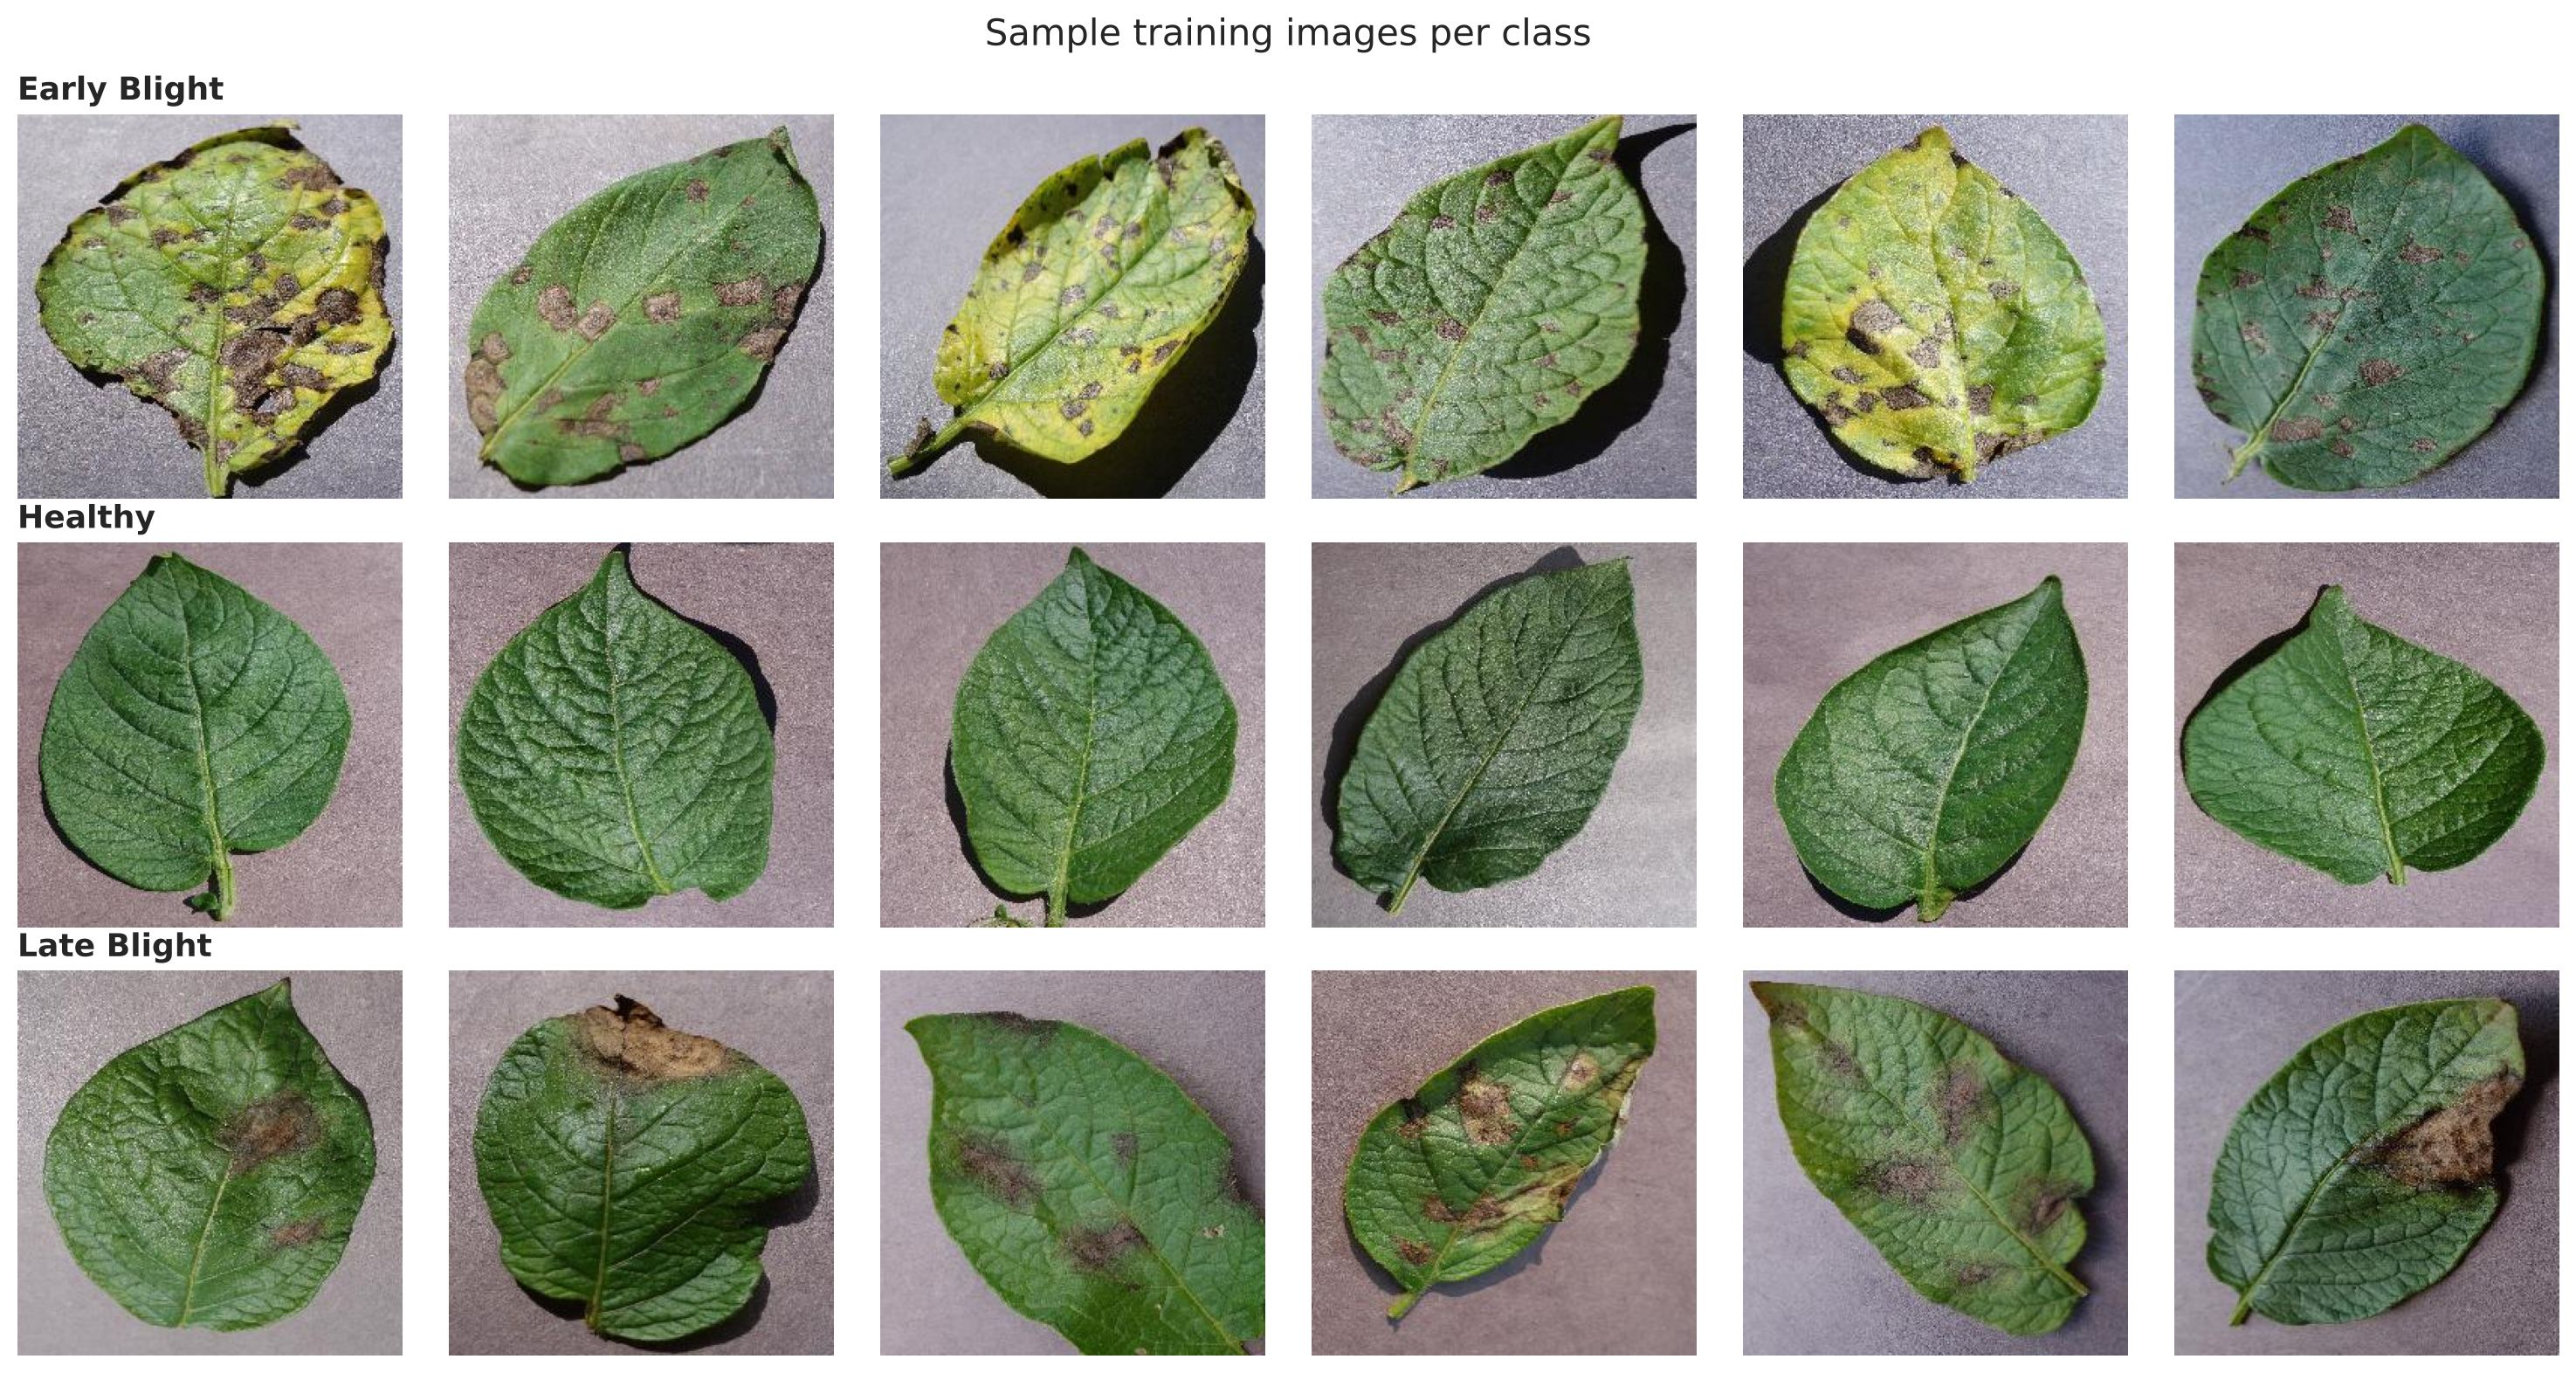

In [3]:
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for r, c in enumerate(CLASSES):
    files = sorted((TRAIN_DIR / c).glob("*"))
    for k, f in enumerate(random.Random(r).sample(files, 6)):
        axes[r, k].imshow(plt.imread(f)); axes[r, k].axis("off")
        if k == 0: axes[r, k].set_title(CLASS_DISPLAY[c], loc="left", fontsize=13, fontweight="bold")
plt.suptitle("Sample training images per class", fontsize=15); plt.tight_layout()
plt.savefig(FIG_DIR / "samples.jpg", dpi=90); plt.show()

In [4]:
# Raw image properties: are all images the same size / mode?
from PIL import Image
props = []
for p, label in prep.list_images(TRAIN_DIR):
    with Image.open(p) as im:
        props.append((label, im.size, im.mode))
props = pd.DataFrame(props, columns=["label", "size", "mode"])
print(props.groupby(["size", "mode"]).size())

size        mode
(256, 256)  RGB     1506
dtype: int64


All raw images are 256×256 RGB JPEGs, but photos uploaded by users later will not be, which is why the preprocessing
step always re-decodes, converts to RGB and resizes.

### 2.1 Class distribution

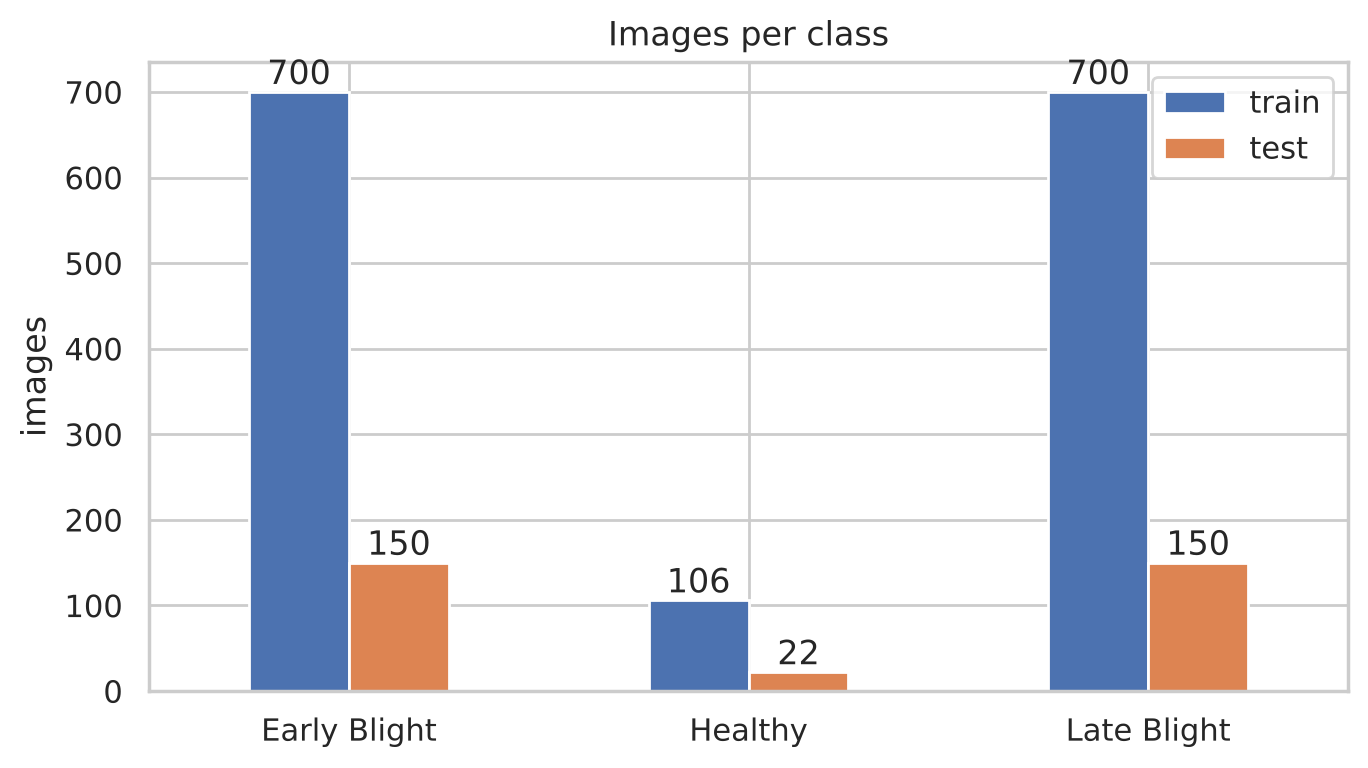

In [5]:
ax = counts.drop("Total").drop(columns="incoming").plot.bar(figsize=(7, 4), color=["#4c72b0", "#dd8452"], rot=0)
ax.set_title("Images per class"); ax.set_ylabel("images")
for cont in ax.containers: ax.bar_label(cont)
plt.tight_layout(); plt.savefig(FIG_DIR / "class_distribution.png", dpi=90); plt.show()

**Interpretation.** The data is **imbalanced**: only ~7 % of the images are healthy leaves (106 of 1,506 in train).
A model could reach ~93 % accuracy while never predicting *Healthy*. So accuracy alone is misleading here. We
(1) train with **class weights**, (2) report **macro** precision / recall / F1, which weight every class equally, and
(3) inspect the confusion matrix.

### 2.2 Interpretable image features

To understand *what* separates the classes, four hand-crafted features are computed on the leaf pixels
(the grey background is masked out by saturation). See `src/insights.py`.

In [6]:
feats = feature_table(TRAIN_DIR)
feats["class"] = feats.label.map(CLASS_DISPLAY)
feats.groupby("class")[FEATURES].agg(["mean", "median"]).round(3)

green_ratio        lesion_fraction        texture         \
                    mean median            mean median    mean median   
class                                                                   
Early Blight       0.398  0.399           0.284  0.198   0.431  0.428   
Healthy            0.437  0.435           0.014  0.007   0.393  0.400   
Late Blight        0.403  0.404           0.206  0.159   0.356  0.358   

             brightness         
                   mean median  
class                           
Early Blight      0.547  0.544  
Healthy           0.462  0.458  
Late Blight       0.425  0.425

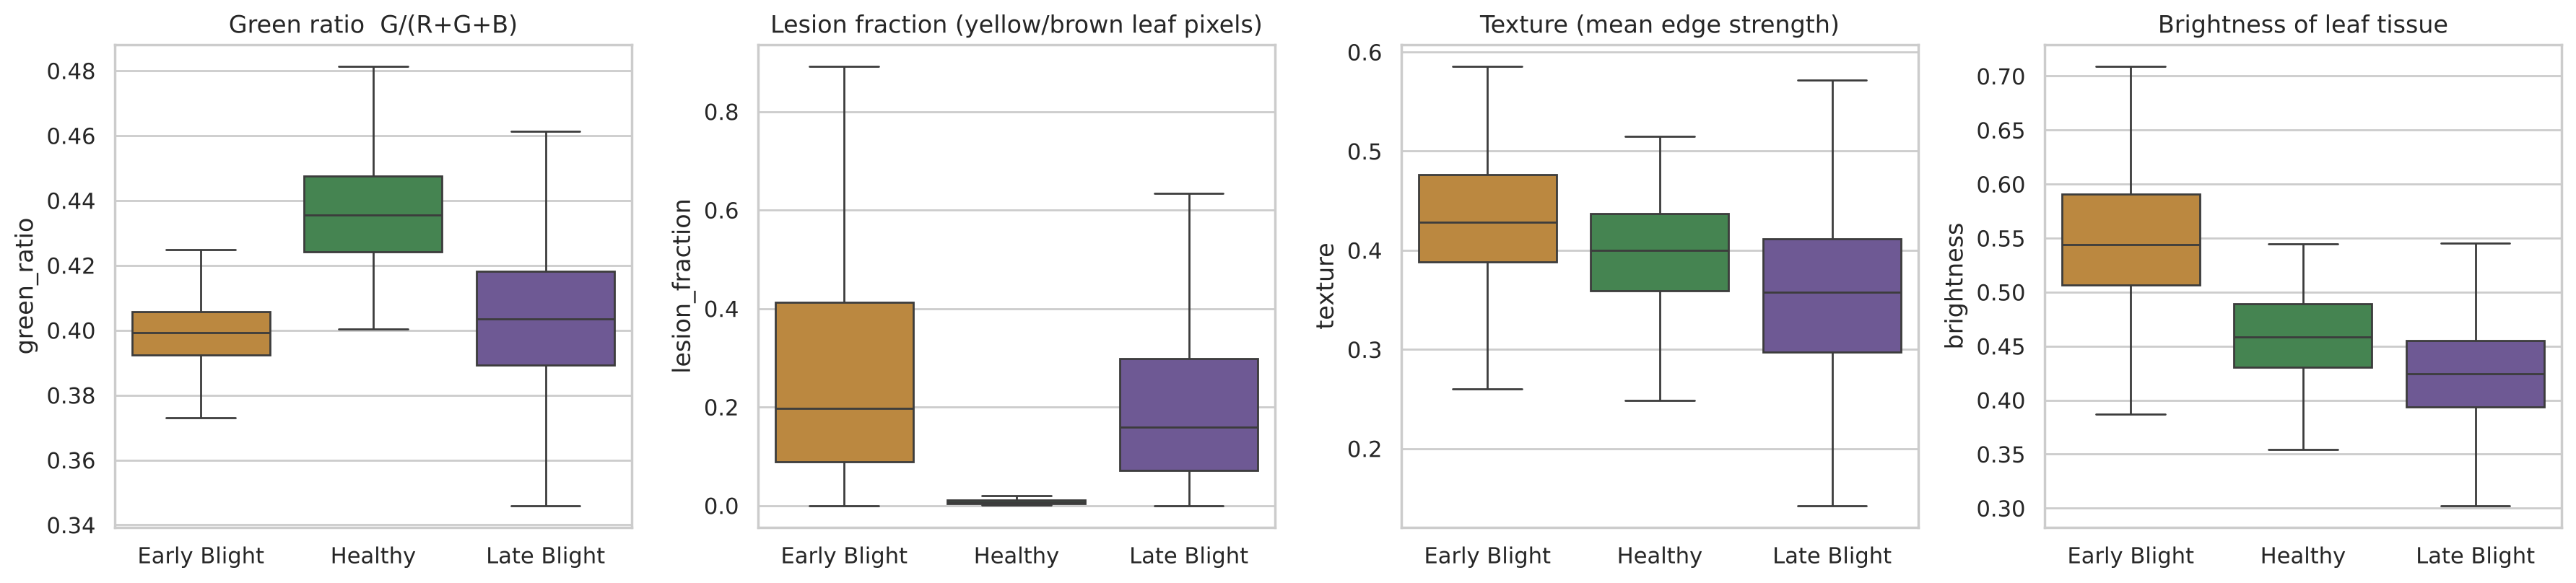

In [7]:
titles = {"green_ratio": "Green ratio  G/(R+G+B)", "lesion_fraction": "Lesion fraction (yellow/brown leaf pixels)",
          "texture": "Texture (mean edge strength)", "brightness": "Brightness of leaf tissue"}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, f in zip(axes, FEATURES):
    sns.boxplot(data=feats, x="class", y=f, hue="class", palette=PALETTE, ax=ax, showfliers=False, legend=False)
    ax.set_title(titles[f]); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "features.png", dpi=90); plt.show()

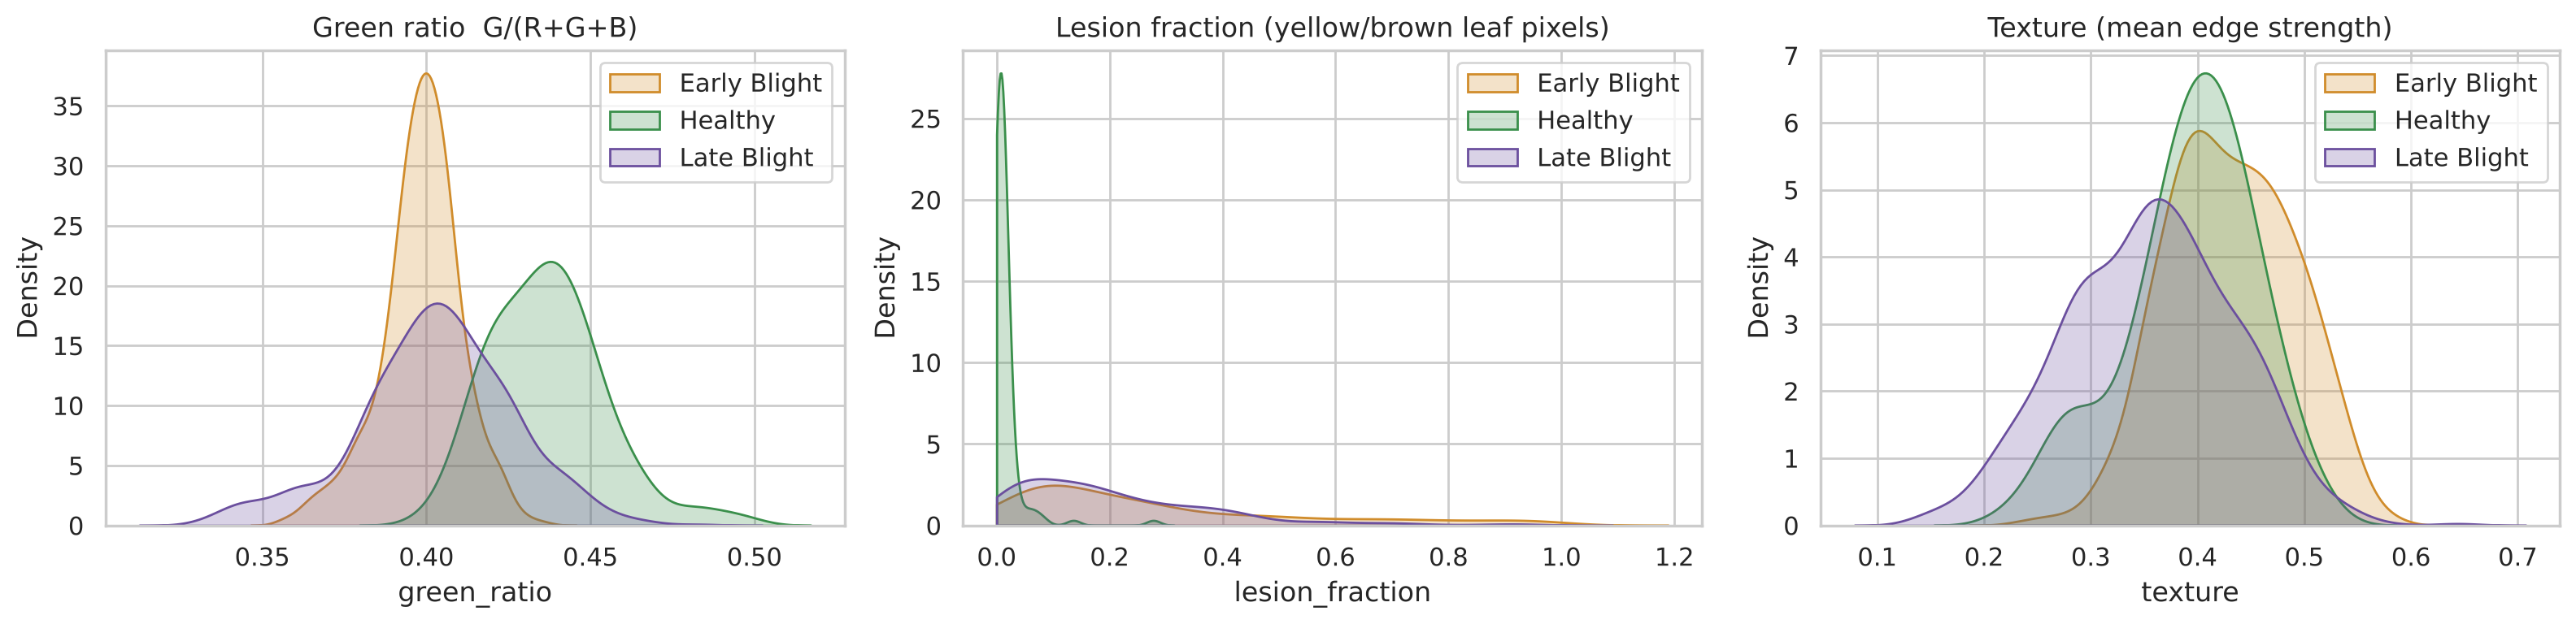

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, f in zip(axes, ["green_ratio", "lesion_fraction", "texture"]):
    for cls, g in feats.groupby("class"):
        sns.kdeplot(g[f], ax=ax, label=cls, color=PALETTE[cls], fill=True, alpha=.25, common_norm=False, clip=(0, None))
    ax.set_title(titles[f]); ax.legend()
plt.tight_layout(); plt.show()

**What story do the features tell?**

1. **Green ratio: healthy leaves are measurably greener.** Healthy leaves have a median green ratio of about 0.435,
   against roughly 0.40 for both blights. Disease destroys chlorophyll, so infected tissue shifts from green towards
   yellow and brown. This feature separates *healthy vs diseased* well, but it can hardly tell the two blights apart:
   their distributions overlap almost completely.

2. **Lesion fraction: how much of the leaf is dead tissue.** Healthy leaves have almost no yellow/brown pixels
   (median ≈ 0.7 %). Both blights have large lesion areas (median ≈ 16–20 %). Early blight has the widest spread
   (std ≈ 0.26), because it starts as small spots and ends as large yellowed (chlorotic) areas. This is the strongest
   single signal of disease.

3. **Texture: early blight is the "busiest" surface, late blight the smoothest.** Early blight makes small, dark
   spots with **concentric rings** ("target spots") that create many edges (median texture ≈ 0.43). Late blight makes
   large, dark, **water-soaked patches** with soft edges, so its leaves are the least textured (≈ 0.36). This is the
   feature that best separates *early vs late blight*, and colour features alone cannot do that.

4. **Brightness** completes the picture: early-blight leaves are the brightest (yellowing), late-blight leaves the
   darkest (necrotic, dark brown/black lesions).

**Takeaway.** No single feature separates all three classes: colour features split healthy from diseased, and
texture and brightness split the two blights. A CNN that learns **colour and local texture at once** is therefore a
good fit, and the imbalance seen in 2.1 means we must judge it on macro-F1, not only accuracy.

## 3. Data preprocessing

`src/preprocessing.py` is shared by the notebook, the API and the retraining job, so training and serving
use exactly the same transformation:

1. **Decode** raw bytes with PIL and apply the EXIF orientation (phone photos are often rotated).
2. **Force RGB**: drops alpha channels and converts grayscale to RGB.
3. **Resize** to 128×128 (bilinear). This cuts compute by 4× compared with 256×256 while keeping the lesion detail.
4. Store as **uint8**, which is 4× less memory than float32.
5. **Inside the model:** a `Rescaling(1/255)` layer normalises pixels to [0, 1], and **augmentation layers**
   (random flips, ±15 % rotation, zoom and contrast) run only during training.
6. **Stratified train / validation split** (85 / 15) so the rare *Healthy* class appears in both.
7. **Class weights** (`balanced`) to counter the imbalance.

In [9]:
X_full, y_full, _ = prep.load_directory(TRAIN_DIR)
X_test, y_test, test_paths = prep.load_directory(TEST_DIR)
X_train, X_val, y_train, y_val = train_test_split(X_full, y_full, test_size=0.15, stratify=y_full, random_state=SEED)
print("train", X_train.shape, X_train.dtype, "| val", X_val.shape, "| test", X_test.shape)
print("pixel range:", X_train.min(), "-", X_train.max())
cw = M.class_weights(y_train)
print("class weights:", {CLASSES[k]: round(v, 2) for k, v in cw.items()})

train (1280, 128, 128, 3) uint8 | val (226, 128, 128, 3) | test (322, 128, 128, 3)
pixel range: 0 - 252
class weights: {'early_blight': 0.72, 'healthy': 4.74, 'late_blight': 0.72}


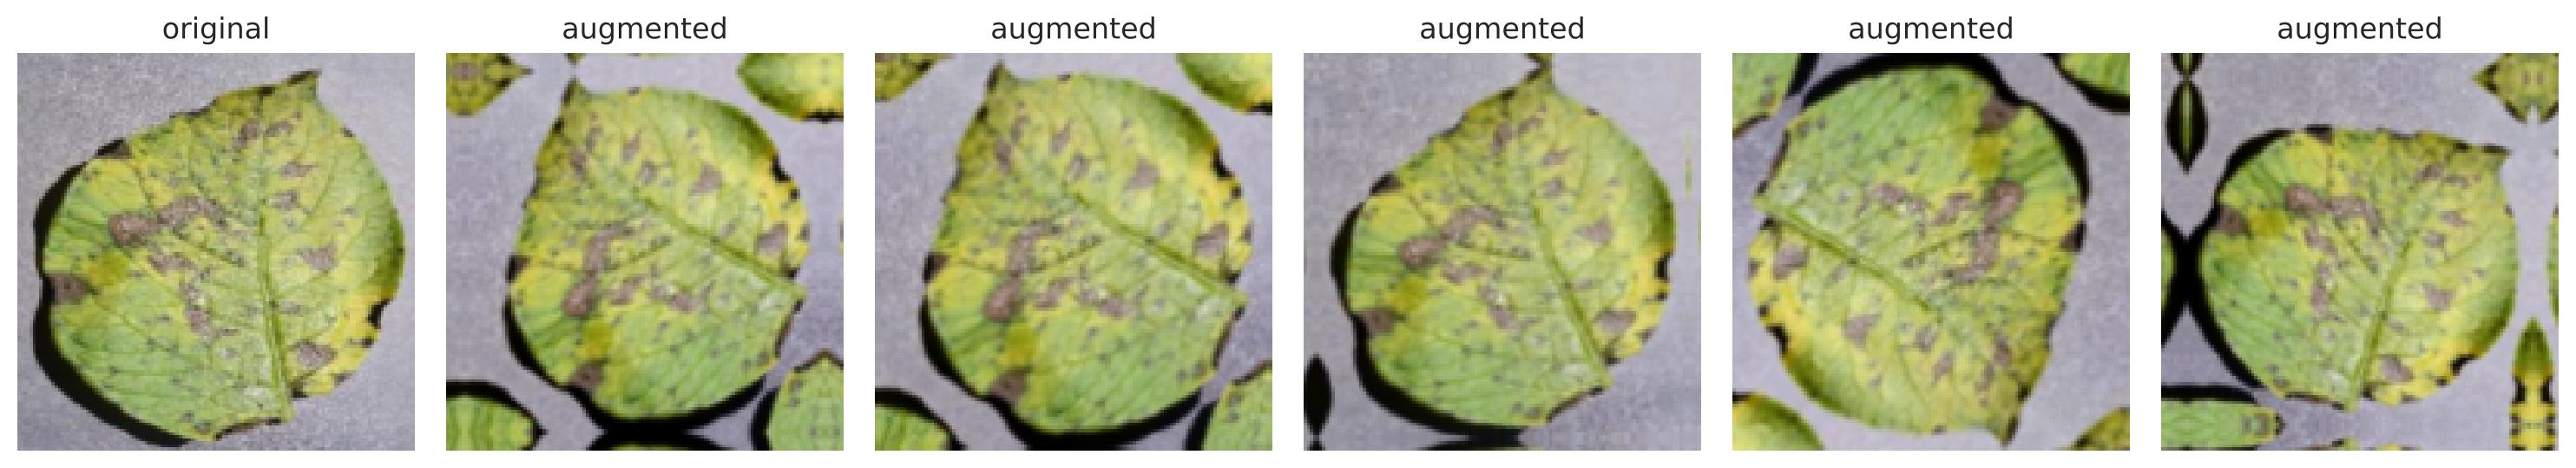

In [10]:
# What augmentation does to one image (training only)
aug = M._augmentation()
img = X_train[np.where(y_train == CLASSES.index("early_blight"))[0][0]]
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(img); axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(np.clip(aug(img[None].astype("float32"), training=True)[0].numpy(), 0, 255).astype("uint8")); ax.set_title("augmented")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Model creation

### 4.1 Baseline: a "vanilla" CNN
Three conv blocks, Flatten, Dense, plain SGD, **no** augmentation, regularisation, class weights or early stopping.
It sets the bar the optimised model has to beat.

In [11]:
baseline = M.build_baseline()
t0 = time.time()
h_base = baseline.fit(M.make_dataset(X_train, y_train), validation_data=M.make_dataset(X_val, y_val, shuffle=False),
                      epochs=12, verbose=2)
print(f"baseline trained in {time.time()-t0:.0f}s, params={baseline.count_params():,}")

Epoch 1/12


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


40/40 - 9s - 216ms/step - accuracy: 0.5008 - loss: 0.9011 - val_accuracy: 0.5575 - val_loss: 0.8689


Epoch 2/12


40/40 - 8s - 197ms/step - accuracy: 0.5836 - loss: 0.8502 - val_accuracy: 0.6903 - val_loss: 0.8226


Epoch 3/12


... (16 outputs left out)

40/40 - 8s - 196ms/step - accuracy: 0.8516 - loss: 0.3774 - val_accuracy: 0.8673 - val_loss: 0.3361


Epoch 12/12


40/40 - 8s - 207ms/step - accuracy: 0.8469 - loss: 0.3748 - val_accuracy: 0.8894 - val_loss: 0.3340


baseline trained in 103s, params=4,288,067


### 4.2 Optimised CNN

| Technique | Why |
|---|---|
| Data augmentation (flip, rotate, zoom, contrast) | More varied training data, so the model generalises to real field photos |
| BatchNormalization after every conv, **momentum 0.9** | Stable gradients, faster convergence. With the Keras default momentum (0.99) a first run collapsed: 95 % train accuracy but validation stuck on one class, because the moving statistics used at inference lagged behind the fast-changing weights. Momentum 0.9 fixed it. |
| L2 weight decay (1e-4) | Penalises large weights (regularisation) |
| Dropout 0.4 / 0.2 | Regularisation in the classifier head |
| GlobalAveragePooling (not Flatten) | ~0.4 M params instead of ~4 M, so less overfitting |
| **Adam** optimiser (lr 1e-3) | Adaptive learning rates |
| **EarlyStopping** (patience 8, restore best weights) | Stops when validation loss stops improving |
| **ReduceLROnPlateau** (×0.5 after 3 flat epochs) | Fine-grained convergence |
| Class weights | Counter the 7 % *Healthy* class |

In [12]:
model = M.build_model()
model.summary()

Model: "potato_leaf_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 128, 128, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 64, 64, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 32, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 16, 16, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probs (Dense)                   │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,139 (1.61 MB)

 Trainable params: 422,179 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [13]:
history, secs = M.train(model, X_train, y_train, X_val, y_val, epochs=40, patience=8, verbose=2)
print(f"trained {len(history.history['loss'])} epochs in {secs/60:.1f} min")

Epoch 1/40


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


40/40 - 22s - 548ms/step - accuracy: 0.8180 - loss: 0.5159 - val_accuracy: 0.8540 - val_loss: 0.5573 - learning_rate: 0.0010


Epoch 2/40


40/40 - 20s - 509ms/step - accuracy: 0.9102 - loss: 0.2549 - val_accuracy: 0.8584 - val_loss: 0.3926 - learning_rate: 0.0010


Epoch 3/40


... (72 outputs left out)

40/40 - 40s - 1s/step - accuracy: 0.9914 - loss: 0.0676 - val_accuracy: 0.9956 - val_loss: 0.0549 - learning_rate: 3.1250e-05


Epoch 40/40


40/40 - 21s - 527ms/step - accuracy: 0.9867 - loss: 0.0807 - val_accuracy: 1.0000 - val_loss: 0.0541 - learning_rate: 1.5625e-05


trained 40 epochs in 16.4 min


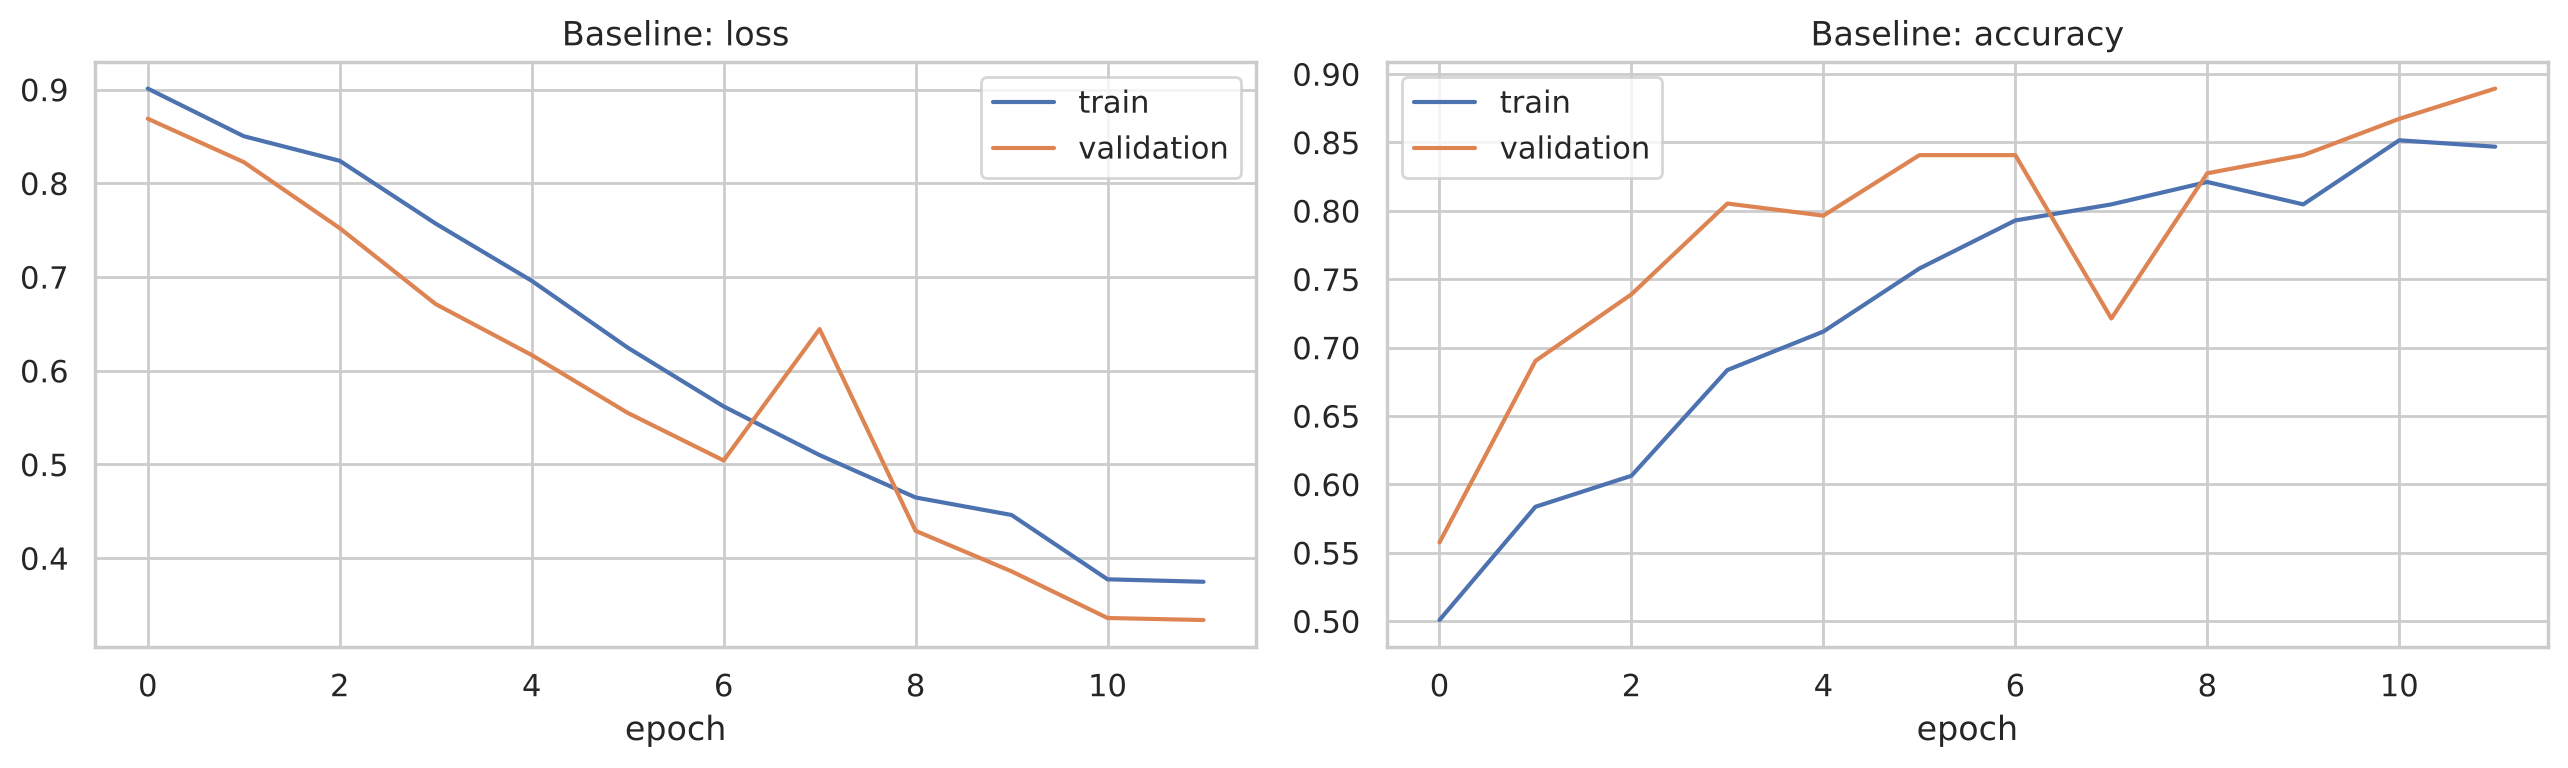

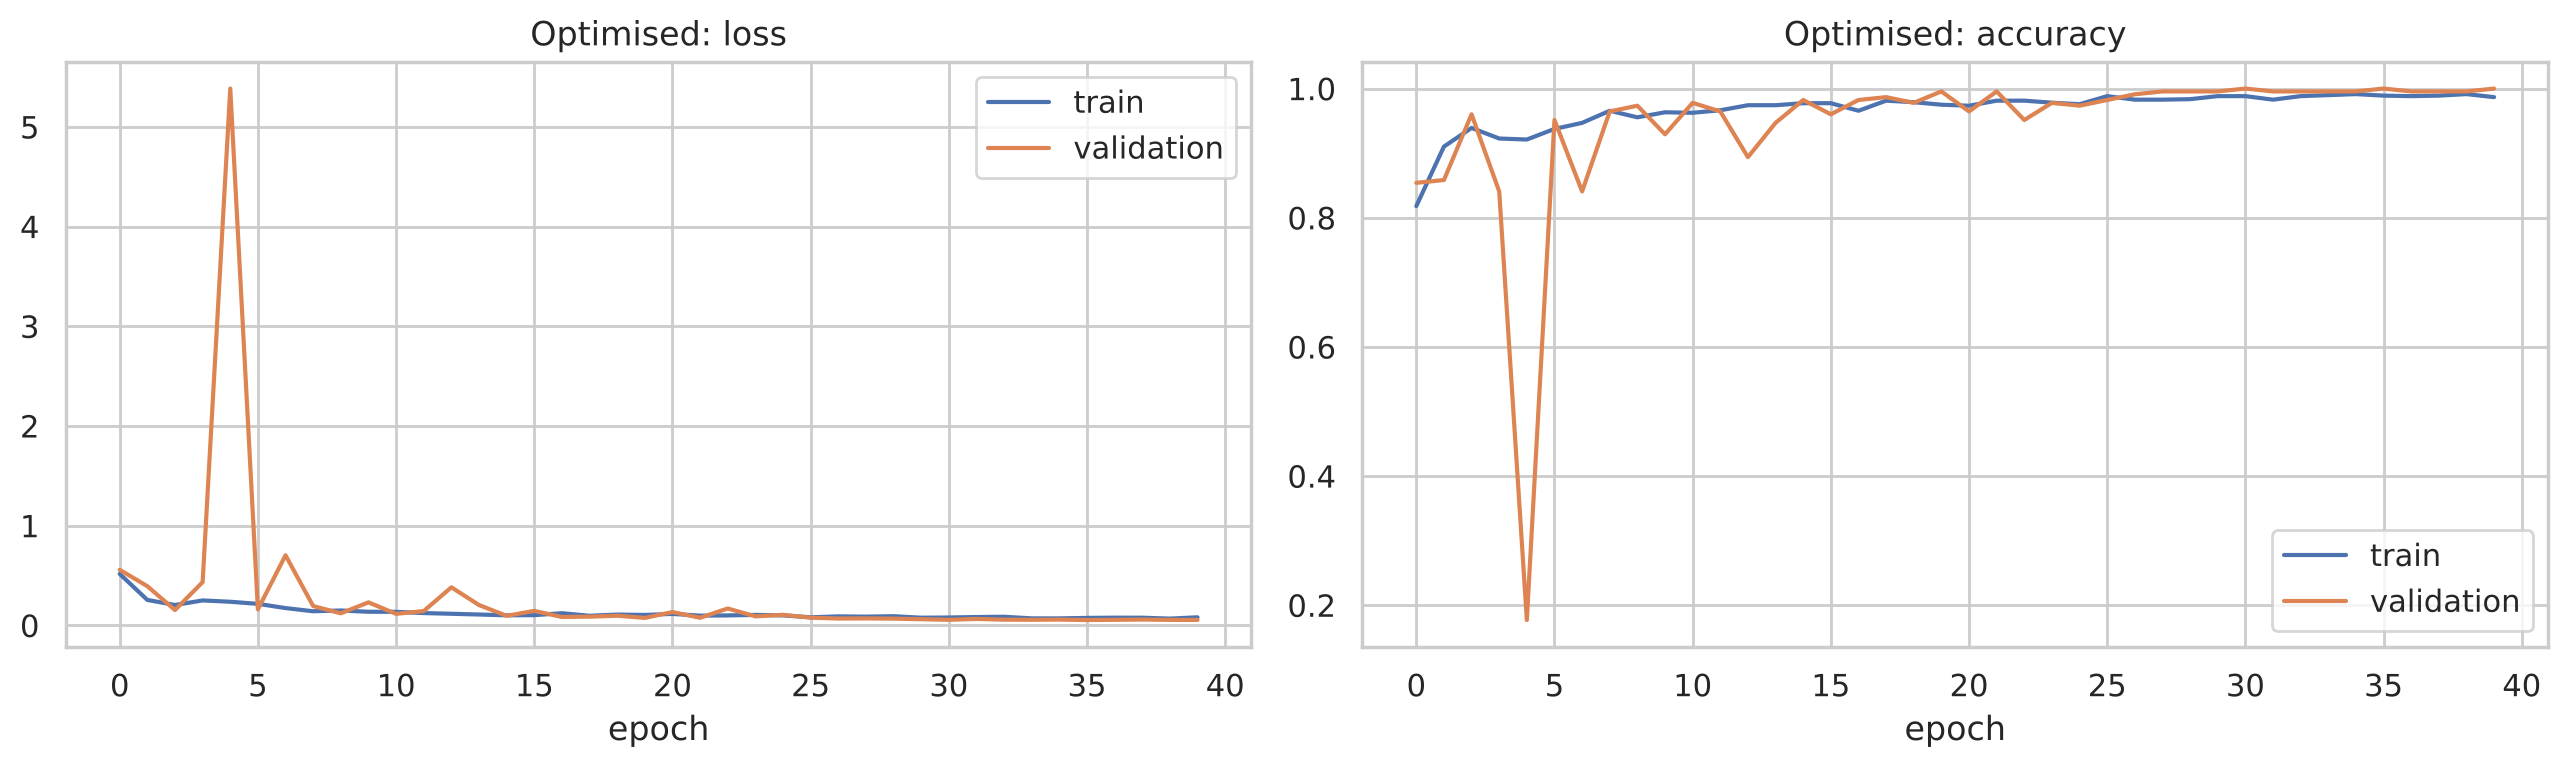

In [14]:
def plot_history(h, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, m in zip(axes, ["loss", "accuracy"]):
        ax.plot(h.history[m], label="train"); ax.plot(h.history["val_" + m], label="validation")
        ax.set_title(f"{title}: {m}"); ax.set_xlabel("epoch"); ax.legend()
    plt.tight_layout()
plot_history(h_base, "Baseline"); plt.show()
plot_history(history, "Optimised"); plt.savefig(FIG_DIR / "learning_curves.png", dpi=90); plt.show()

## 5. Model testing / evaluation

Both models are evaluated on the **held-out test set** (322 images never used for training or model selection).
Metrics: **accuracy, loss (cross-entropy), precision, recall, F1** (macro and weighted), **ROC-AUC** (one-vs-rest),
the confusion matrix and the per-class report.

In [15]:
m_base = M.evaluate(baseline, X_test, y_test)
m_opt = M.evaluate(model, X_test, y_test)
keys = ["accuracy", "loss", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "roc_auc_ovr"]
comparison = pd.DataFrame({"Baseline CNN": [m_base[k] for k in keys], "Optimised CNN": [m_opt[k] for k in keys]}, index=keys)
comparison.round(4)

,Baseline CNN,Optimised CNN
accuracy,0.8944,0.9907
loss,0.3051,0.0253
precision_macro,0.9257,0.9600
recall_macro,0.8598,0.9933
f1_macro,0.8878,0.9754
f1_weighted,0.8942,0.9909
roc_auc_ovr,0.9773,0.9998


In [16]:
print(classification_report(y_test, M.predict_proba(model, X_test).argmax(1),
                            target_names=[CLASS_DISPLAY[c] for c in CLASSES], digits=4))

              precision    recall  f1-score   support

Early Blight     1.0000    1.0000    1.0000       150
     Healthy     0.8800    1.0000    0.9362        22
 Late Blight     1.0000    0.9800    0.9899       150

    accuracy                         0.9907       322
   macro avg     0.9600    0.9933    0.9754       322
weighted avg     0.9918    0.9907    0.9909       322



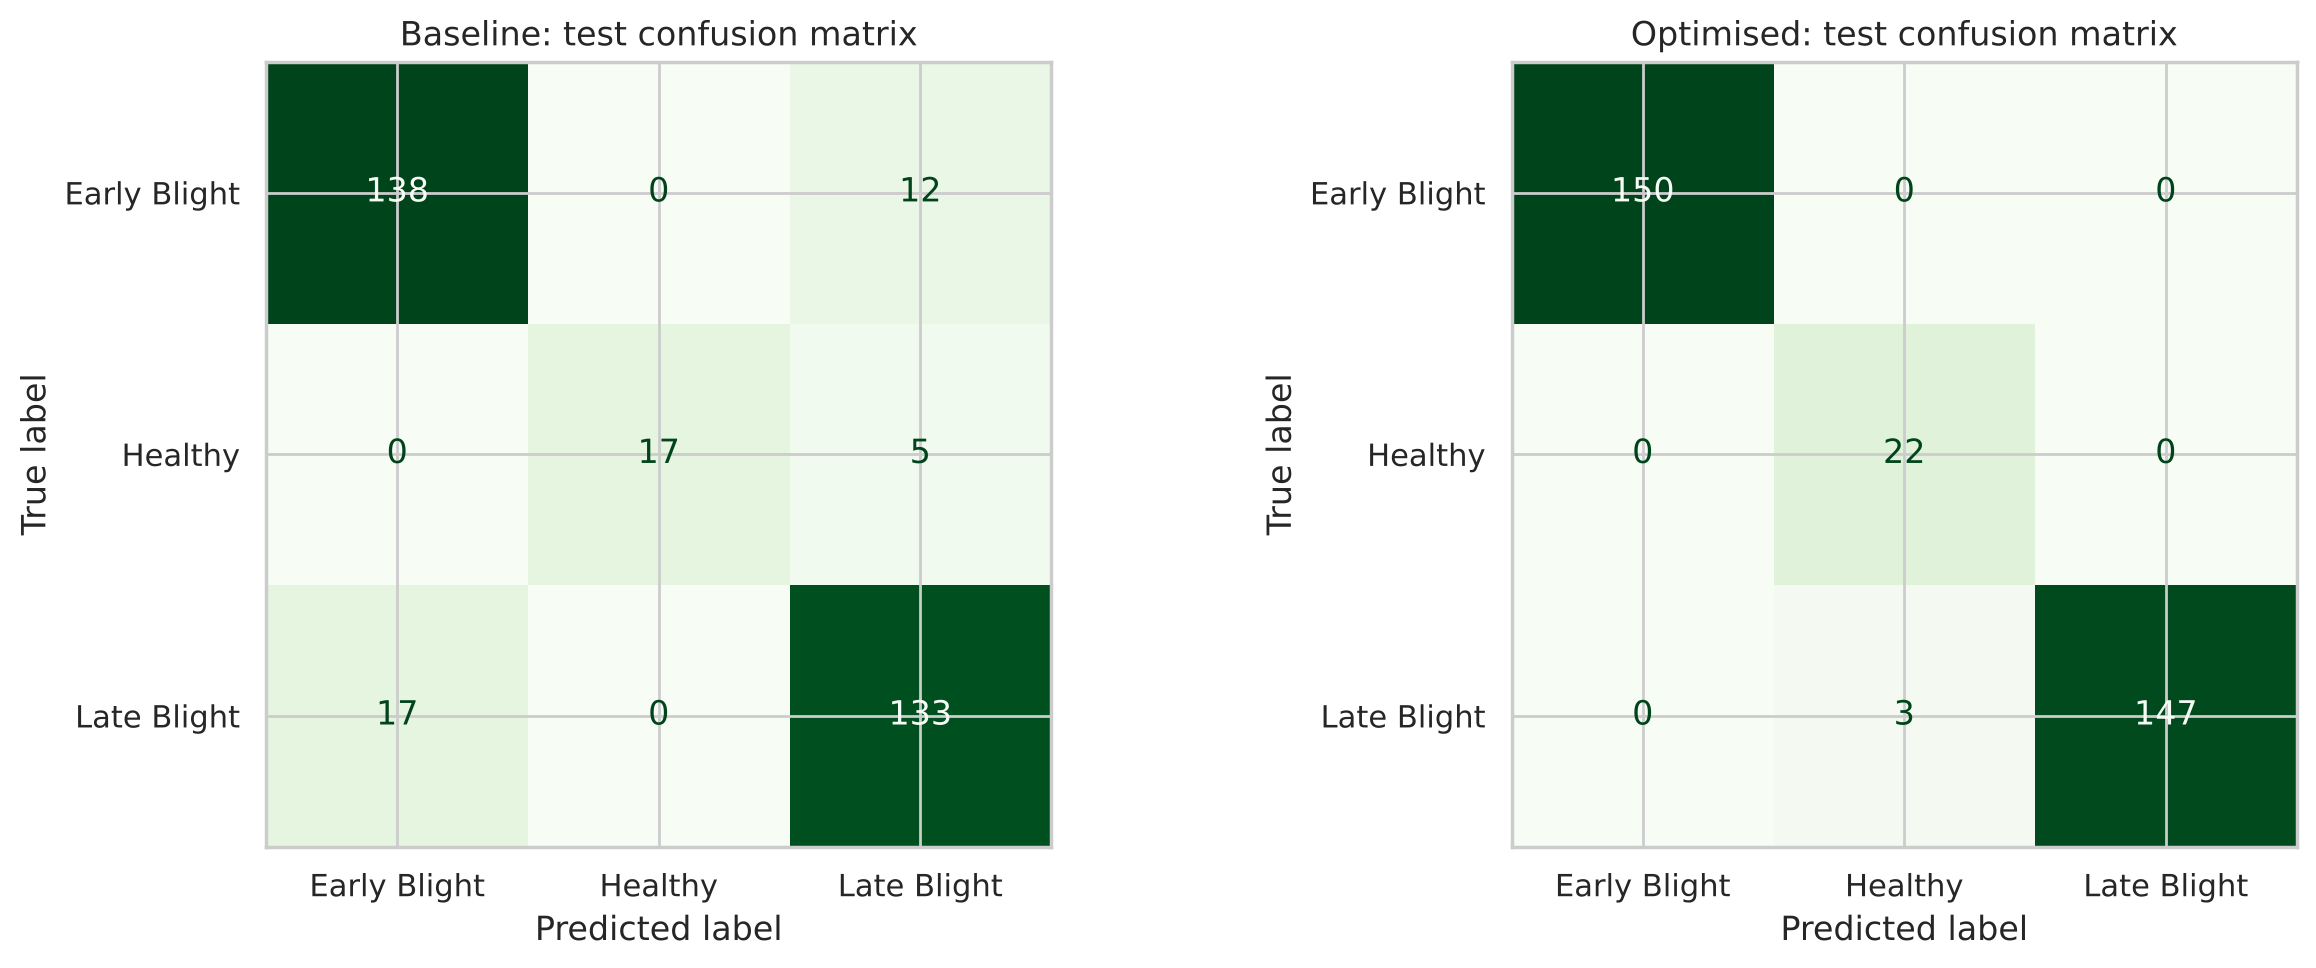

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
names = [CLASS_DISPLAY[c] for c in CLASSES]
for ax, (title, m) in zip(axes, [("Baseline", m_base), ("Optimised", m_opt)]):
    ConfusionMatrixDisplay(np.array(m["confusion_matrix"]), display_labels=names).plot(ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(f"{title}: test confusion matrix")
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=90); plt.show()

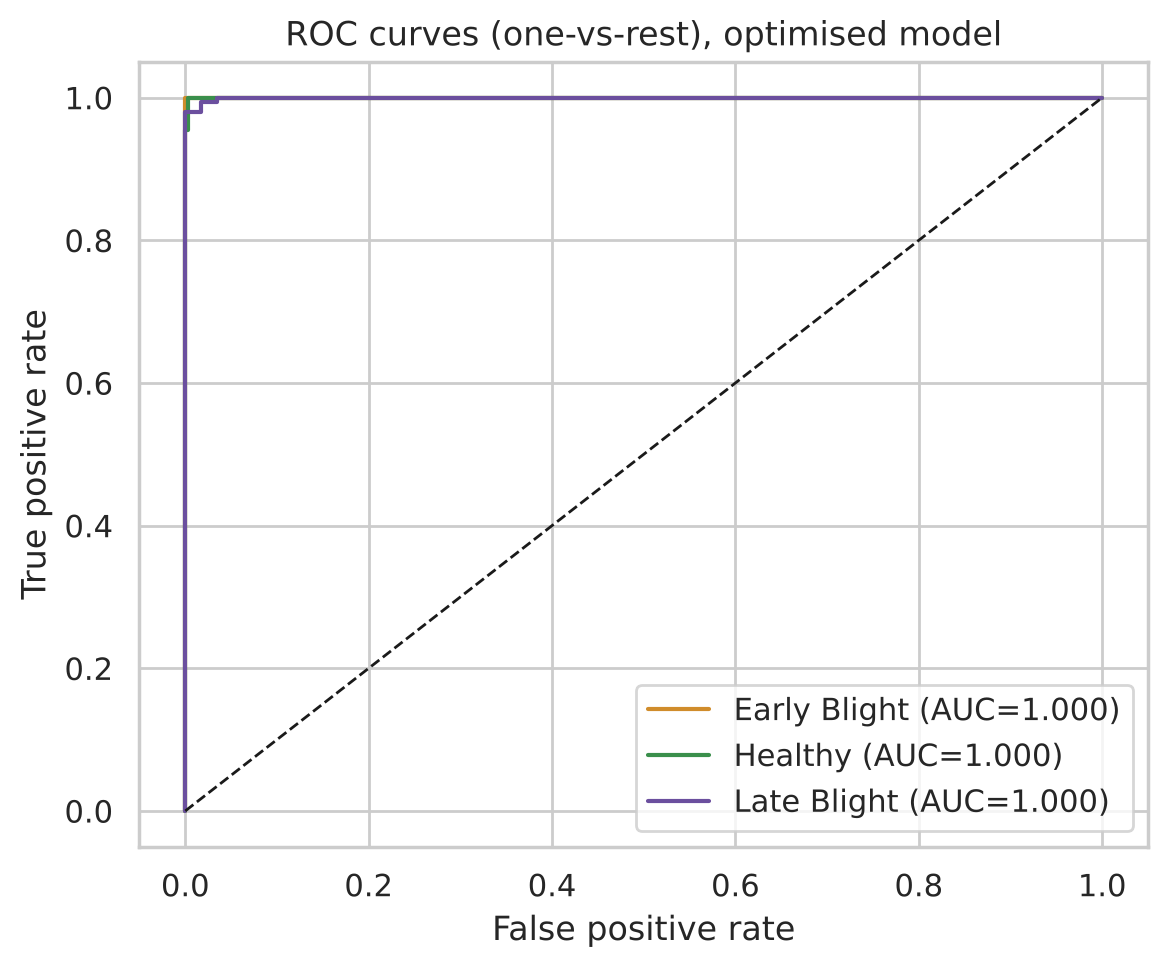

In [18]:
proba = M.predict_proba(model, X_test)
plt.figure(figsize=(6, 5))
for i, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_test == i, proba[:, i])
    plt.plot(fpr, tpr, label=f"{CLASS_DISPLAY[c]} (AUC={auc(fpr, tpr):.3f})", color=PALETTE[CLASS_DISPLAY[c]])
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves (one-vs-rest), optimised model"); plt.legend(); plt.tight_layout(); plt.show()

In [19]:
print(f"Optimised model on the test set: accuracy {m_opt['accuracy']:.2%}, macro-F1 {m_opt['f1_macro']:.3f}, "
      f"macro-recall {m_opt['recall_macro']:.3f}, ROC-AUC {m_opt['roc_auc_ovr']:.4f}")
print(f"Baseline: accuracy {m_base['accuracy']:.2%}, macro-F1 {m_base['f1_macro']:.3f}")
print("Healthy-class recall: baseline", round(m_base['per_class']['healthy']['recall'], 3),
      "-> optimised", round(m_opt['per_class']['healthy']['recall'], 3))

Optimised model on the test set: accuracy 99.07%, macro-F1 0.975, macro-recall 0.993, ROC-AUC 0.9998
Baseline: accuracy 89.44%, macro-F1 0.888
Healthy-class recall: baseline 0.773 -> optimised 1.0


**How good is the model?** On the 322 held-out test images the optimised CNN reaches **99.07 % accuracy**,
test loss **0.025**, macro precision **0.960**, macro recall **0.993**, macro-F1 **0.975** and ROC-AUC **0.9998**.
The vanilla baseline reaches 89.4 % accuracy and 0.888 macro-F1, so every optimisation technique was worth it.

* Every early-blight and every healthy test leaf is classified correctly. Healthy recall rises from 0.77 (baseline) to 1.00.
* The only 3 errors are **late-blight leaves predicted as healthy**. These are typically very early infections with
  small, faint lesions, the lowest-lesion-fraction cases in the EDA. In the field this is the costlier kind of error
  (a missed infection), so a production rule could flag *Healthy* predictions below ~90 % confidence for a second photo.
* The baseline mostly confused early and late blight (29 errors). The optimised model removed that confusion,
  which is consistent with the EDA: separating the blights needs texture, which augmentation and the deeper
  conv stack capture better.

### 5.1 Save the model (`models/potato_cnn.h5`), metadata and dataset insights for the API/UI

In [20]:
from src.config import MODEL_PATH
meta = M.save_model(model, m_opt, version=1, extra={
    "history": [{"version": 1, "run_id": None, "accuracy": m_opt["accuracy"], "f1_macro": m_opt["f1_macro"], "trained_on_new": 0}],
    "trigger": "notebook", "baseline_test_metrics": {k: m_base[k] for k in keys}})
interpretations = {
  "class_counts": "Only ~7% of images are healthy leaves. Accuracy alone would hide a model that ignores this class, so the model is trained with class weights and judged on macro-F1.",
  "green_ratio": "Healthy leaves are measurably greener (median G/(R+G+B) ~0.435 vs ~0.40). Disease destroys chlorophyll. This separates healthy from diseased, but not early from late blight.",
  "lesion_fraction": "Healthy leaves have almost no yellow/brown tissue (~1%), while blighted leaves have 16-20% (median). Early blight varies most, from a few spots to large yellowed areas.",
  "texture": "Early blight's concentric 'target' spots create the most edges; late blight's large, soft, water-soaked patches are the smoothest. Texture is what tells the two blights apart.",
  "brightness": "Early-blight leaves are brightest (yellowing); late-blight leaves darkest (necrotic lesions)."
}
save_insights(interpretations, df=feats)
print("saved", MODEL_PATH.name, f"({MODEL_PATH.stat().st_size/1e6:.1f} MB)  version", meta["version"])

saved potato_cnn.h5 (5.2 MB)  version 1


## 6. Prediction functions

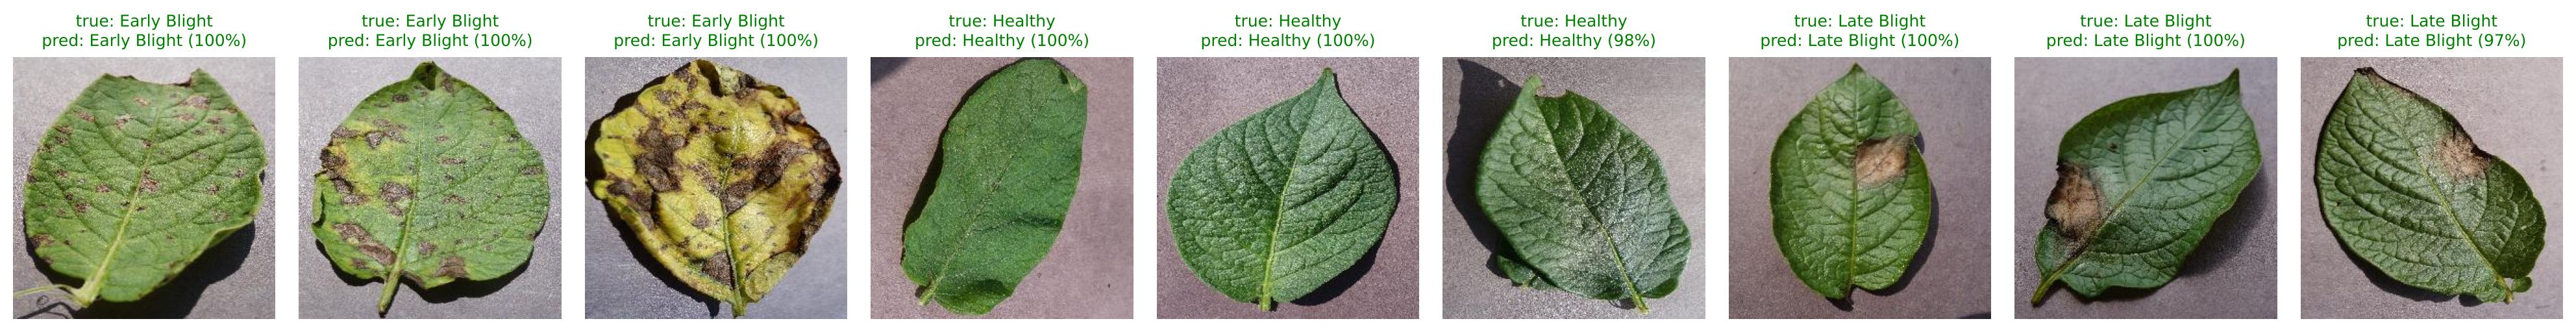

In [21]:
from src.prediction import Predictor
predictor = Predictor()               # loads models/potato_cnn.h5 from disk, as the API does

rng = random.Random(7)
samples = [p for c in CLASSES for p in rng.sample(sorted((TEST_DIR / c).glob('*')), 3)]
fig, axes = plt.subplots(1, 9, figsize=(20, 3.2))
for ax, p in zip(axes, samples):
    res = predictor.predict_path(p)
    true = CLASS_DISPLAY[p.parent.name]
    ax.imshow(plt.imread(p)); ax.axis("off")
    ax.set_title(f"true: {true}\npred: {res['display_label']} ({res['confidence']:.0%})",
                 color="green" if res["display_label"] == true else "red", fontsize=9)
plt.tight_layout(); plt.show()

In [22]:
# Single-datapoint prediction, exactly what POST /predict returns
one = sorted((TEST_DIR / "late_blight").glob("*"))[0]
json.dumps(predictor.predict_bytes(one.read_bytes()), indent=2)

'{\n  "label": "late_blight",\n  "display_label": "Late Blight",\n  "confidence": 0.9993335604667664,\n  "probabilities": {\n    "Early Blight": 0.0006392048671841621,\n    "Healthy": 2.7153781047672965e-05,\n    "Late Blight": 0.9993335604667664\n  },\n  "model_version": 1\n}'

## 7. Retraining demonstration

The production retraining job (`src/retrain.py`, triggered by the UI button or automatically after
`RETRAIN_THRESHOLD` uploads) does the following:

1. Reads the newly uploaded labelled images from the **SQLite database**.
2. Runs them through the **same preprocessing**.
3. Mixes in a replay sample of the original training data, so the model does not forget what it already learned.
4. **Loads the saved custom model as the pre-trained starting point** and fine-tunes it (Adam, lr 1e-4, early stopping).
5. Evaluates old vs new on the untouched test set and **promotes the new version only if it is not worse**.

Here the same steps run in memory on `data/incoming` (the 15 % of data held back to simulate new field photos),
without overwriting the saved model, so the notebook can be re-run safely.

In [23]:
X_new, y_new, _ = prep.load_directory(INCOMING_DIR)
X_rep, y_rep, _ = prep.load_directory(TRAIN_DIR, limit_per_class=120, seed=1)
X_rt, y_rt = np.concatenate([X_new, X_rep]), np.concatenate([y_new, y_rep])
Xa, Xb, ya, yb = train_test_split(X_rt, y_rt, test_size=0.15, stratify=y_rt, random_state=SEED)

finetuned = M.load_model()                       # the saved custom model = pre-trained model
M.compile_model(finetuned, lr=1e-4)
h_rt = finetuned.fit(M.make_dataset(Xa, ya), validation_data=M.make_dataset(Xb, yb, shuffle=False), epochs=8,
                     class_weight=M.class_weights(ya), verbose=2,
                     callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
m_rt = M.evaluate(finetuned, X_test, y_test)
pd.DataFrame({"v1 (current)": [m_opt[k] for k in keys], "v2 (retrained)": [m_rt[k] for k in keys]}, index=keys).round(4)

Epoch 1/8


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


18/18 - 12s - 649ms/step - accuracy: 0.9789 - loss: 0.0977 - val_accuracy: 1.0000 - val_loss: 0.0552


Epoch 2/8


18/18 - 10s - 528ms/step - accuracy: 0.9895 - loss: 0.0876 - val_accuracy: 1.0000 - val_loss: 0.0518


Epoch 3/8


... (2 outputs left out)

18/18 - 9s - 517ms/step - accuracy: 0.9807 - loss: 0.1038 - val_accuracy: 1.0000 - val_loss: 0.0545


Epoch 5/8


18/18 - 10s - 553ms/step - accuracy: 0.9859 - loss: 0.0881 - val_accuracy: 1.0000 - val_loss: 0.0523


,v1 (current),v2 (retrained)
accuracy,0.9907,0.9907
loss,0.0253,0.0316
precision_macro,0.9600,0.9700
recall_macro,0.9933,0.9933
f1_macro,0.9754,0.9810
f1_weighted,0.9909,0.9908
roc_auc_ovr,0.9998,0.9997


The fine-tuned model is compared with the current one on the same test set. In production the job promotes it
only if `accuracy_new >= accuracy_old - 0.01`, archives the old model to `models/archive/`, and every API worker
hot-reloads the new file.

**Summary.** Data acquisition → EDA with interpretable features → shared preprocessing → regularised, optimised
CNN → evaluation with 7 metrics → saved `.h5` model → prediction helpers → retraining from the saved model.
The same `src/` modules power the FastAPI service and web UI described in the README.